In [1]:

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from tqdm.auto import tqdm

# Project paths
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
ROBUSTNESS_DIR = OUTPUT_DIR / "robustness"

ROBUSTNESS_DIR.mkdir(parents=True, exist_ok=True)

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Image configuration
IMG_HEIGHT = 64
IMG_WIDTH = 64
IMG_CHANNELS = 3
NUM_CLASSES = 43

print("Project root:", PROJECT_ROOT)
print("TensorFlow:", tf.__version__)
print("Image size:", IMG_HEIGHT, "x", IMG_WIDTH)
print("Number of classes:", NUM_CLASSES)


Project root: c:\Projects\Traffic_Sign_Recognition
TensorFlow: 2.21.0
Image size: 64 x 64
Number of classes: 43


In [2]:

train_df = pd.read_csv(PROCESSED_DIR / "train_metadata.csv")
val_df = pd.read_csv(PROCESSED_DIR / "validation_metadata.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test_metadata.csv")

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nSample records:")
display(train_df.head())


Training: (31367, 9)
Validation: (7842, 9)
Testing: (12630, 9)

Training columns:
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path', 'ImagePath']

Sample records:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path,ImagePath
0,56,56,5,5,51,51,12,Train/12/00012_00031_00018.png,c:\Projects\Traffic_Sign_Recognition\data\raw\...
1,27,28,6,5,22,23,5,Train/5/00005_00031_00001.png,c:\Projects\Traffic_Sign_Recognition\data\raw\...
2,92,94,8,9,84,86,12,Train/12/00012_00069_00028.png,c:\Projects\Traffic_Sign_Recognition\data\raw\...
3,60,53,6,5,54,48,13,Train/13/00013_00052_00022.png,c:\Projects\Traffic_Sign_Recognition\data\raw\...
4,64,58,6,5,59,53,18,Train/18/00018_00017_00024.png,c:\Projects\Traffic_Sign_Recognition\data\raw\...


In [3]:

def preprocess_image(image_path, image_size=(64, 64)):
    """
    Load and preprocess one traffic sign image.

    Steps:
    1. Read image using OpenCV.
    2. Convert BGR to RGB.
    3. Resize to 64x64.
    4. Normalize pixel values to [0, 1].
    """

    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Unable to read image: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    image = cv2.resize(
        image,
        image_size,
        interpolation=cv2.INTER_AREA
    )

    image = image.astype(np.float32) / 255.0

    return image


# Test preprocessing on one image
sample_path = train_df.iloc[0]["ImagePath"]

sample_image = preprocess_image(sample_path)

print("Processed image shape:", sample_image.shape)
print("Data type:", sample_image.dtype)
print("Minimum pixel value:", sample_image.min())
print("Maximum pixel value:", sample_image.max())


Processed image shape: (64, 64, 3)
Data type: float32
Minimum pixel value: 0.05490196
Maximum pixel value: 0.2509804


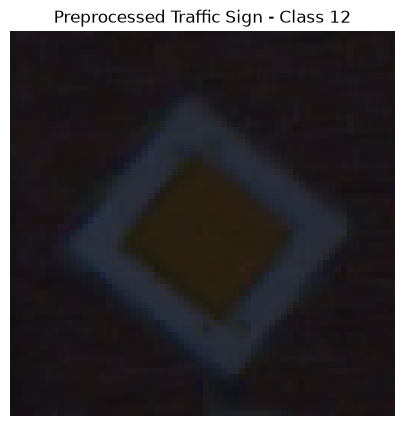

In [4]:

plt.figure(figsize=(5, 5))

plt.imshow(sample_image)
plt.title(
    f"Preprocessed Traffic Sign - Class {train_df.iloc[0]['ClassId']}"
)
plt.axis("off")
plt.show()


In [5]:

BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)
print("Image dimensions:", (IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS))


Batch size: 64
Number of classes: 43
Image dimensions: (64, 64, 3)


In [6]:

def load_and_preprocess_image(image_path, label):
    # Read image from disk
    image_bytes = tf.io.read_file(image_path)

    # Decode PNG image into RGB
    image = tf.io.decode_png(image_bytes, channels=3)

    # Convert pixel values from uint8 [0, 255] to float32 [0, 1]
    image = tf.image.convert_image_dtype(image, tf.float32)

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH]
    )

    # Convert integer class label to one-hot vector
    label = tf.one_hot(label, depth=NUM_CLASSES)

    return image, label


In [7]:

def create_tf_dataset(dataframe, batch_size=64, training=False):
    image_paths = dataframe["ImagePath"].astype(str).values
    labels = dataframe["ClassId"].astype(np.int32).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    # Shuffle only the training data
    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(dataframe), 10000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    # Load and preprocess images
    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    # Group images into batches
    dataset = dataset.batch(batch_size)

    # Prefetch batches to improve pipeline performance
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


In [8]:

train_dataset = create_tf_dataset(
    train_df,
    batch_size=BATCH_SIZE,
    training=True
)

val_dataset = create_tf_dataset(
    val_df,
    batch_size=BATCH_SIZE,
    training=False
)

test_dataset = create_tf_dataset(
    test_df,
    batch_size=BATCH_SIZE,
    training=False
)

print("TensorFlow datasets created successfully!")


TensorFlow datasets created successfully!


In [9]:

# Get one batch from the training dataset
images, labels = next(iter(train_dataset))

print("IMAGE BATCH")
print("Shape:", images.shape)
print("Data type:", images.dtype)
print("Minimum pixel value:", float(tf.reduce_min(images)))
print("Maximum pixel value:", float(tf.reduce_max(images)))

print("\nLABEL BATCH")
print("Shape:", labels.shape)
print("Data type:", labels.dtype)
print("Example one-hot label:", labels[0].numpy())
print("Decoded class ID:", int(tf.argmax(labels[0])))


IMAGE BATCH
Shape: (64, 64, 64, 3)
Data type: <dtype: 'float32'>
Minimum pixel value: 0.00021446123719215393
Maximum pixel value: 1.0

LABEL BATCH
Shape: (64, 43)
Data type: <dtype: 'float32'>
Example one-hot label: [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Decoded class ID: 1


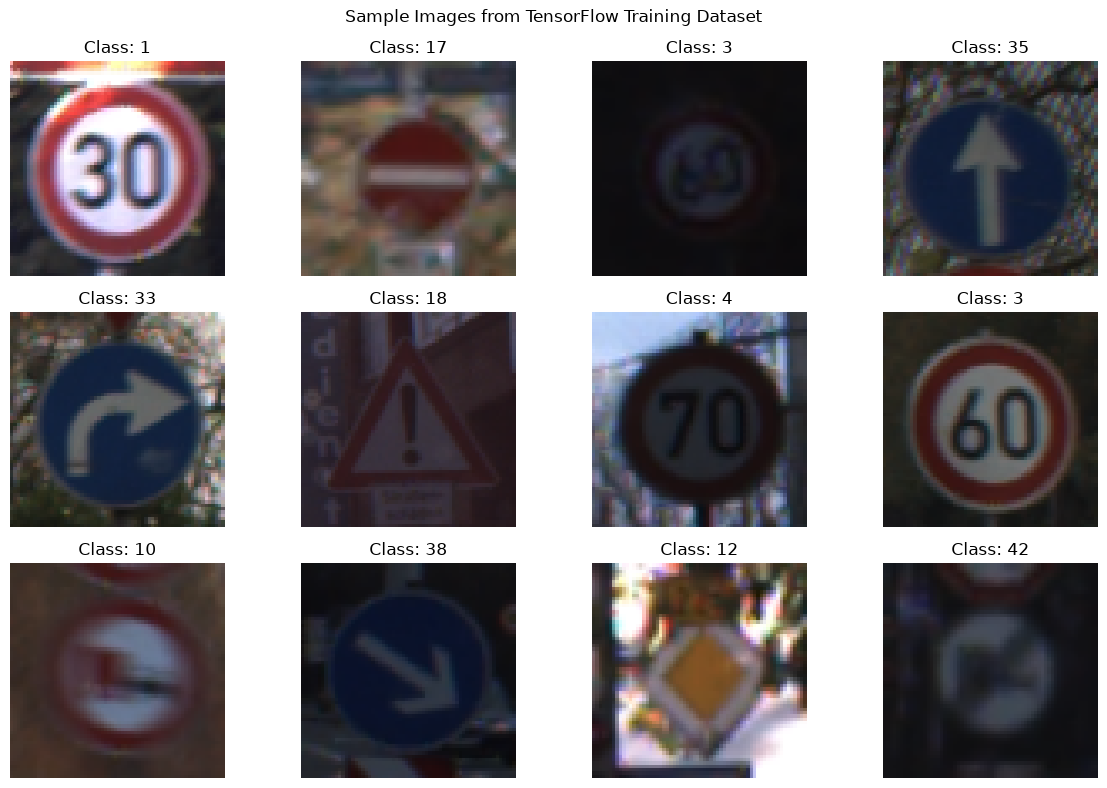

In [10]:

plt.figure(figsize=(12, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)

    plt.imshow(images[i].numpy())
    class_id = int(tf.argmax(labels[i]))

    plt.title(f"Class: {class_id}")
    plt.axis("off")

plt.suptitle("Sample Images from TensorFlow Training Dataset")
plt.tight_layout()
plt.show()


In [11]:

from tensorflow.keras import layers

standard_augmentation = tf.keras.Sequential([
    layers.RandomRotation(
        factor=0.04,
        fill_mode="nearest",
        seed=SEED
    ),

    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="nearest",
        seed=SEED
    ),

    layers.RandomZoom(
        height_factor=0.08,
        width_factor=0.08,
        fill_mode="nearest",
        seed=SEED
    ),

    layers.RandomContrast(
        factor=0.10,
        seed=SEED
    ),

    layers.RandomBrightness(
        factor=0.10,
        value_range=(0, 1),
        seed=SEED
    )
], name="standard_augmentation")

print("Standard augmentation pipeline created!")


Standard augmentation pipeline created!


In [12]:

heavy_augmentation = tf.keras.Sequential([
    layers.RandomRotation(
        factor=0.08,
        fill_mode="nearest",
        seed=SEED
    ),

    layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="nearest",
        seed=SEED
    ),

    layers.RandomZoom(
        height_factor=0.15,
        width_factor=0.15,
        fill_mode="nearest",
        seed=SEED
    ),

    layers.RandomContrast(
        factor=0.25,
        seed=SEED
    ),

    layers.RandomBrightness(
        factor=0.20,
        value_range=(0, 1),
        seed=SEED
    )
], name="heavy_augmentation")

print("Heavy augmentation pipeline created!")


Heavy augmentation pipeline created!


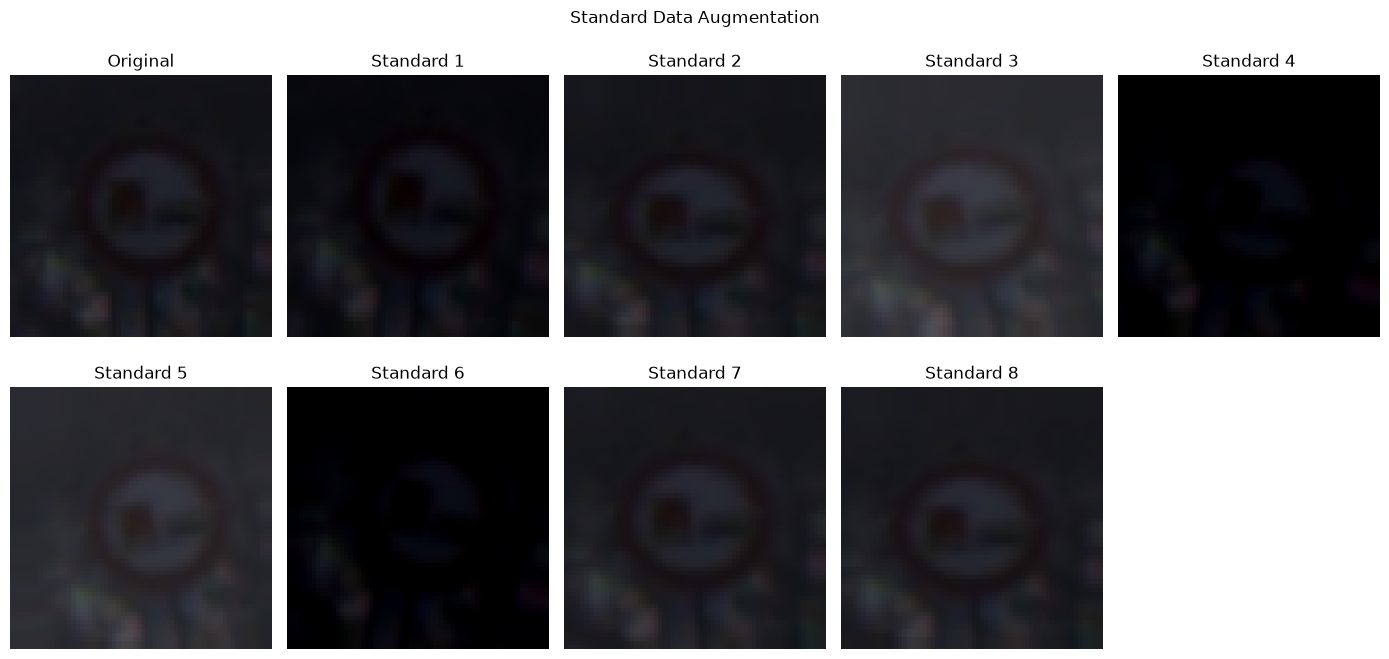

In [13]:

# Get a batch of original images
sample_images, sample_labels = next(iter(train_dataset))

# Select one original image
original_image = sample_images[0]

# Generate 8 augmented versions
standard_images = [
    standard_augmentation(
        tf.expand_dims(original_image, axis=0),
        training=True
    )[0].numpy()
    for _ in range(8)
]

plt.figure(figsize=(14, 7))

plt.subplot(2, 5, 1)
plt.imshow(original_image.numpy())
plt.title("Original")
plt.axis("off")

for i, augmented_image in enumerate(standard_images):
    plt.subplot(2, 5, i + 2)
    plt.imshow(np.clip(augmented_image, 0, 1))
    plt.title(f"Standard {i + 1}")
    plt.axis("off")

plt.suptitle("Standard Data Augmentation")
plt.tight_layout()
plt.show()


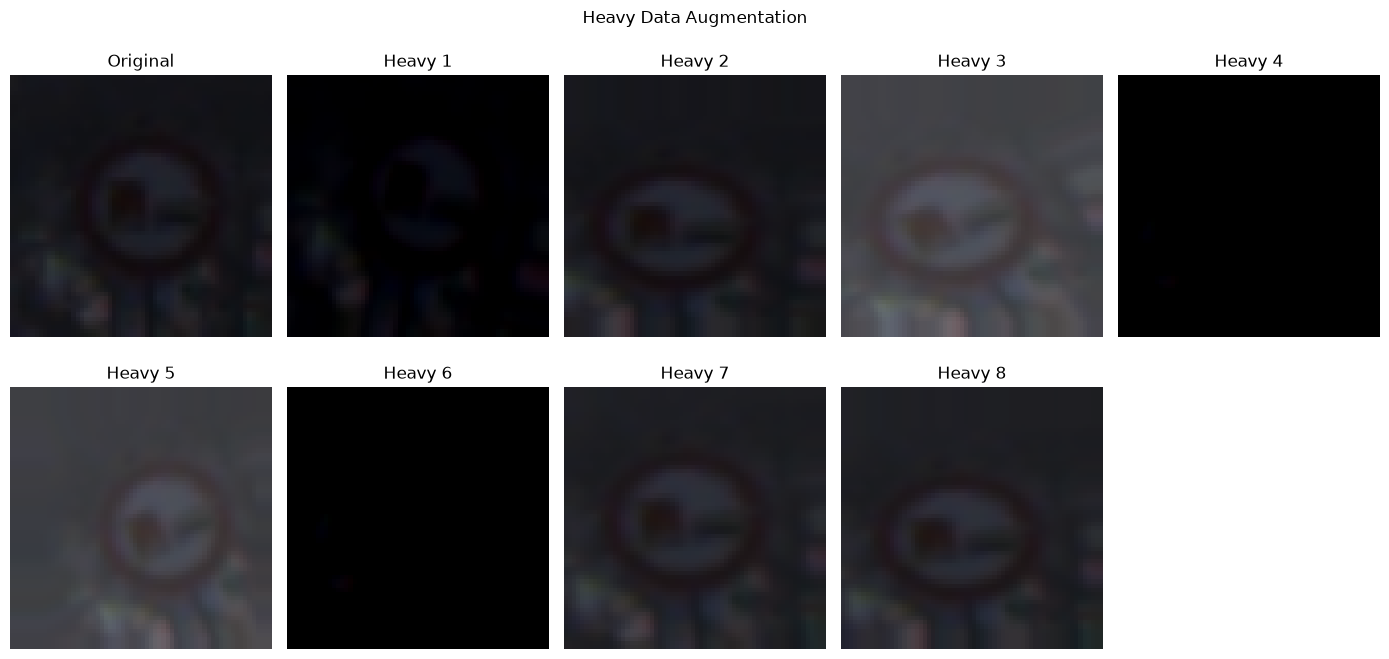

In [14]:

heavy_images = [
    heavy_augmentation(
        tf.expand_dims(original_image, axis=0),
        training=True
    )[0].numpy()
    for _ in range(8)
]

plt.figure(figsize=(14, 7))

plt.subplot(2, 5, 1)
plt.imshow(original_image.numpy())
plt.title("Original")
plt.axis("off")

for i, augmented_image in enumerate(heavy_images):
    plt.subplot(2, 5, i + 2)
    plt.imshow(np.clip(augmented_image, 0, 1))
    plt.title(f"Heavy {i + 1}")
    plt.axis("off")

plt.suptitle("Heavy Data Augmentation")
plt.tight_layout()
plt.show()


In [15]:

def apply_augmentation(images, labels, augmentation_layer):
    images = augmentation_layer(images, training=True)
    images = tf.clip_by_value(images, 0.0, 1.0)
    return images, labels


def create_augmented_dataset(
    dataframe,
    augmentation_layer,
    batch_size=BATCH_SIZE
):
    dataset = create_tf_dataset(
        dataframe,
        batch_size=batch_size,
        training=True
    )

    dataset = dataset.map(
        lambda images, labels: apply_augmentation(
            images,
            labels,
            augmentation_layer
        ),
        num_parallel_calls=AUTOTUNE
    )

    return dataset.prefetch(AUTOTUNE)


train_dataset_standard = create_augmented_dataset(
    train_df,
    standard_augmentation
)

train_dataset_heavy = create_augmented_dataset(
    train_df,
    heavy_augmentation
)

print("Standard augmented training dataset created.")
print("Heavy augmented training dataset created.")
print("Validation and test datasets remain unchanged.")


Standard augmented training dataset created.
Heavy augmented training dataset created.
Validation and test datasets remain unchanged.


In [16]:

standard_batch, standard_labels = next(iter(train_dataset_standard))
heavy_batch, heavy_labels = next(iter(train_dataset_heavy))

print("STANDARD AUGMENTATION")
print("Image shape:", standard_batch.shape)
print("Label shape:", standard_labels.shape)
print("Pixel range:",
      float(tf.reduce_min(standard_batch)),
      "to",
      float(tf.reduce_max(standard_batch)))

print("\nHEAVY AUGMENTATION")
print("Image shape:", heavy_batch.shape)
print("Label shape:", heavy_labels.shape)
print("Pixel range:",
      float(tf.reduce_min(heavy_batch)),
      "to",
      float(tf.reduce_max(heavy_batch)))


STANDARD AUGMENTATION
Image shape: (64, 64, 64, 3)
Label shape: (64, 43)
Pixel range: 0.0 to 1.0

HEAVY AUGMENTATION
Image shape: (64, 64, 64, 3)
Label shape: (64, 43)
Pixel range: 0.0 to 1.0


In [17]:
# Folder for corrupted test images and their metadata
CORRUPTED_DATA_DIR = PROCESSED_DIR / "robustness_test"

CORRUPTION_TYPES = [
    "gaussian_blur",
    "brightness",
    "occlusion",
    "combined"
]

for corruption in CORRUPTION_TYPES:
    folder = CORRUPTED_DATA_DIR / corruption
    folder.mkdir(parents=True, exist_ok=True)

print("Corrupted test-data folders created:")
for corruption in CORRUPTION_TYPES:
    print(CORRUPTED_DATA_DIR / corruption)

Corrupted test-data folders created:
c:\Projects\Traffic_Sign_Recognition\data\processed\robustness_test\gaussian_blur
c:\Projects\Traffic_Sign_Recognition\data\processed\robustness_test\brightness
c:\Projects\Traffic_Sign_Recognition\data\processed\robustness_test\occlusion
c:\Projects\Traffic_Sign_Recognition\data\processed\robustness_test\combined


In [18]:
def apply_gaussian_blur(image):
    return cv2.GaussianBlur(image, (5, 5), sigmaX=1.2)


def apply_brightness(image):
    bright_image = image.astype(np.float32) * 1.35
    return np.clip(bright_image, 0, 255).astype(np.uint8)


def apply_occlusion(image, seed=42):
    image = image.copy()

    height, width, _ = image.shape
    rectangle_height = 18
    rectangle_width = 18

    rng = np.random.default_rng(seed)

    y = rng.integers(0, height - rectangle_height + 1)
    x = rng.integers(0, width - rectangle_width + 1)

    image[
        y:y + rectangle_height,
        x:x + rectangle_width
    ] = 0

    return image


def apply_combined_corruption(image, seed=42):
    image = apply_gaussian_blur(image)
    image = apply_brightness(image)
    image = apply_occlusion(image, seed=seed)

    return image


print("All four corruption functions are ready.")

All four corruption functions are ready.


In [19]:
corruption_functions = {
    "gaussian_blur": apply_gaussian_blur,
    "brightness": apply_brightness,
    "occlusion": apply_occlusion,
    "combined": apply_combined_corruption
}

corrupted_metadata = {}

for corruption_name, corruption_function in corruption_functions.items():

    print(f"\nCreating {corruption_name} test dataset...")

    output_folder = CORRUPTED_DATA_DIR / corruption_name

    corrupted_df = test_df.copy()
    corrupted_paths = []

    for index, row in tqdm(
        corrupted_df.iterrows(),
        total=len(corrupted_df),
        desc=corruption_name
    ):
        # Read original image
        image = cv2.imread(str(row["ImagePath"]))

        if image is None:
            raise ValueError(f"Could not read image: {row['ImagePath']}")

        # Convert BGR to RGB and resize to model input size
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (IMG_WIDTH, IMG_HEIGHT))

        # Apply corruption
        if corruption_name in ["occlusion", "combined"]:
            corrupted_image = corruption_function(
                image,
                seed=SEED + int(index)
            )
        else:
            corrupted_image = corruption_function(image)

        # Save corrupted image
        filename = f"test_{index:05d}_class_{int(row['ClassId'])}.png"
        output_path = output_folder / filename

        # Convert RGB back to BGR for OpenCV writing
        success = cv2.imwrite(
            str(output_path),
            cv2.cvtColor(corrupted_image, cv2.COLOR_RGB2BGR)
        )

        if not success:
            raise IOError(f"Could not save image: {output_path}")

        corrupted_paths.append(str(output_path.resolve()))

    # Update metadata with corrupted image paths
    corrupted_df["ImagePath"] = corrupted_paths

    # Save metadata CSV
    metadata_path = output_folder / f"{corruption_name}_metadata.csv"
    corrupted_df.to_csv(metadata_path, index=False)

    corrupted_metadata[corruption_name] = corrupted_df

    print(f"Saved {len(corrupted_df)} images.")
    print(f"Metadata: {metadata_path}")

print("\nAll corrupted test datasets have been created.")


Creating gaussian_blur test dataset...


gaussian_blur:   0%|          | 0/12630 [00:00<?, ?it/s]

Saved 12630 images.
Metadata: c:\Projects\Traffic_Sign_Recognition\data\processed\robustness_test\gaussian_blur\gaussian_blur_metadata.csv

Creating brightness test dataset...


brightness:   0%|          | 0/12630 [00:00<?, ?it/s]

Saved 12630 images.
Metadata: c:\Projects\Traffic_Sign_Recognition\data\processed\robustness_test\brightness\brightness_metadata.csv

Creating occlusion test dataset...


occlusion:   0%|          | 0/12630 [00:00<?, ?it/s]

Saved 12630 images.
Metadata: c:\Projects\Traffic_Sign_Recognition\data\processed\robustness_test\occlusion\occlusion_metadata.csv

Creating combined test dataset...


combined:   0%|          | 0/12630 [00:00<?, ?it/s]

Saved 12630 images.
Metadata: c:\Projects\Traffic_Sign_Recognition\data\processed\robustness_test\combined\combined_metadata.csv

All corrupted test datasets have been created.


In [20]:
print("CORRUPTED DATASET VERIFICATION")
print("-" * 45)

for corruption in CORRUPTION_TYPES:

    folder = CORRUPTED_DATA_DIR / corruption
    metadata_path = folder / f"{corruption}_metadata.csv"

    metadata = pd.read_csv(metadata_path)

    image_count = len(list(folder.glob("*.png")))

    print(f"\n{corruption.upper()}")
    print("Metadata rows:", len(metadata))
    print("Saved images:", image_count)
    print("Unique classes:", metadata["ClassId"].nunique())
    print("Image paths exist:", metadata["ImagePath"].apply(
        lambda path: Path(path).exists()
    ).all())

CORRUPTED DATASET VERIFICATION
---------------------------------------------

GAUSSIAN_BLUR
Metadata rows: 12630
Saved images: 12630
Unique classes: 43
Image paths exist: True

BRIGHTNESS
Metadata rows: 12630
Saved images: 12630
Unique classes: 43
Image paths exist: True

OCCLUSION
Metadata rows: 12630
Saved images: 12630
Unique classes: 43
Image paths exist: True

COMBINED
Metadata rows: 12630
Saved images: 12630
Unique classes: 43
Image paths exist: True


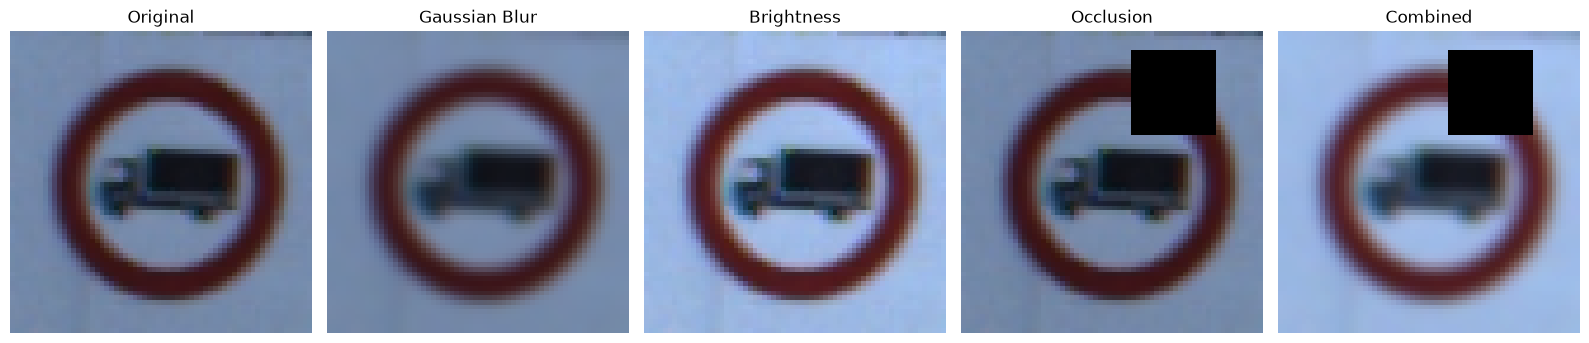

In [21]:
sample_index = 0

original_path = test_df.iloc[sample_index]["ImagePath"]
original_image = cv2.imread(str(original_path))
original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)
original_image = cv2.resize(original_image, (IMG_WIDTH, IMG_HEIGHT))

fig, axes = plt.subplots(1, 5, figsize=(16, 4))

axes[0].imshow(original_image)
axes[0].set_title("Original")

for i, corruption in enumerate(CORRUPTION_TYPES):

    corrupted_path = corrupted_metadata[corruption].iloc[
        sample_index
    ]["ImagePath"]

    image = cv2.imread(str(corrupted_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    axes[i + 1].imshow(image)
    axes[i + 1].set_title(corruption.replace("_", " ").title())

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [22]:
# Verify clean train, validation, and test splits
clean_splits = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

print("CLEAN DATASET VERIFICATION")
print("-" * 45)

for split_name, dataframe in clean_splits.items():

    print(f"\n{split_name}")
    print("Images:", len(dataframe))
    print("Unique classes:", dataframe["ClassId"].nunique())
    print(
        "All image paths exist:",
        dataframe["ImagePath"].apply(lambda p: Path(p).exists()).all()
    )

    assert dataframe["ClassId"].nunique() == NUM_CLASSES
    assert dataframe["ImagePath"].apply(lambda p: Path(p).exists()).all()

# Verify that no image appears in more than one clean split
train_paths = set(train_df["ImagePath"])
val_paths = set(val_df["ImagePath"])
test_paths = set(test_df["ImagePath"])

assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)

print("\nNo overlapping images between the three clean splits.")
print("Clean dataset verification passed!")

CLEAN DATASET VERIFICATION
---------------------------------------------

Train
Images: 31367
Unique classes: 43
All image paths exist: True

Validation
Images: 7842
Unique classes: 43
All image paths exist: True

Test
Images: 12630
Unique classes: 43
All image paths exist: True

No overlapping images between the three clean splits.
Clean dataset verification passed!


In [23]:
import json

phase2_summary = {
    "image_size": [IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS],
    "num_classes": NUM_CLASSES,
    "batch_size": BATCH_SIZE,
    "normalization": "Pixel values scaled to [0, 1]",
    "augmentation_methods": [
        "Standard augmentation",
        "Heavy augmentation"
    ],
    "clean_datasets": {
        "train": len(train_df),
        "validation": len(val_df),
        "test": len(test_df)
    },
    "corrupted_test_datasets": {
        corruption: len(
            pd.read_csv(
                CORRUPTED_DATA_DIR / corruption /
                f"{corruption}_metadata.csv"
            )
        )
        for corruption in CORRUPTION_TYPES
    },
    "corruption_types": CORRUPTION_TYPES,
    "random_seed": SEED
}

summary_path = PROCESSED_DIR / "phase2_preprocessing_summary.json"

with open(summary_path, "w") as file:
    json.dump(phase2_summary, file, indent=4)

print(json.dumps(phase2_summary, indent=4))
print("\nPhase 2 summary saved to:", summary_path)

{
    "image_size": [
        64,
        64,
        3
    ],
    "num_classes": 43,
    "batch_size": 64,
    "normalization": "Pixel values scaled to [0, 1]",
    "augmentation_methods": [
        "Standard augmentation",
        "Heavy augmentation"
    ],
    "clean_datasets": {
        "train": 31367,
        "validation": 7842,
        "test": 12630
    },
    "corrupted_test_datasets": {
        "gaussian_blur": 12630,
        "brightness": 12630,
        "occlusion": 12630,
        "combined": 12630
    },
    "corruption_types": [
        "gaussian_blur",
        "brightness",
        "occlusion",
        "combined"
    ],
    "random_seed": 42
}

Phase 2 summary saved to: c:\Projects\Traffic_Sign_Recognition\data\processed\phase2_preprocessing_summary.json
